# 01 · Data exploration
Coverage and sanity checks of the NSE archive data (prices, delivery, corporate actions, indices) and the SHP XBRL shareholding filings. Every dataset's provenance is in `data/metadata/datasets.json`.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
P = ROOT / 'data' / 'processed'; T = ROOT / 'outputs' / 'tables'

In [2]:
import json
cat = json.loads((ROOT/'data/metadata/datasets.json').read_text())
pd.DataFrame(cat).T[['source_url','coverage_start','coverage_end','n_records','quality_score']]

,source_url,coverage_start,coverage_end,n_records,quality_score
board_meetings,PR*.zip (Bm files),2012-01-04,2026-12-05,120682,0.8
corporate_actions,https://nsearchives.nseindia.com/archives/equi...,2012-01-03,2026-11-25,67224,0.85
fundamentals_yahoo,https://query1.finance.yahoo.com/ws/fundamenta...,2021-12-31,2026-09-30,186135,0.6
index_levels,https://nsearchives.nseindia.com/content/indic...,2012-06-01,2026-11-13,22050,0.9
monthly_panel,derived,2017-12-29,2026-11-13,261207,0.85
prices_daily,https://nsearchives.nseindia.com/content/histo...,2012-01-02,2026-11-13,6242820,0.95
shareholding_quarterly,derived from shp_xbrl,2018-03-31,2026-09-30,31178,0.85
shp_xbrl,https://nsearchives.nseindia.com/corporate/xbr...,2018-01-19,2026-10-27,32999,0.85


In [3]:
px = pd.read_parquet(P/'prices_daily.parquet', columns=['symbol','date','close','value_cr','deliv_pct','ca_flag','dps'])
print(px.shape, px.symbol.nunique(), px.date.min().date(), px.date.max().date())
px.groupby(px.date.dt.year).agg(sessions=('date','nunique'), symbols=('symbol','nunique'), ca_events=('ca_flag','sum'), dividend_events=('dps', lambda s:(s>0).sum()))

(6242820, 7) 3454 2012-01-02 2026-11-13


,sessions,symbols,ca_events,dividend_events
date,,,,
2012,251,1562,38,1111
2013,250,1561,57,1061
2014,244,1555,55,1123
2015,248,1610,110,1047
2016,247,1612,141,1105
2017,248,1665,103,1147
2018,246,1669,83,1160
2019,245,1706,155,1191
2020,252,1751,73,1033


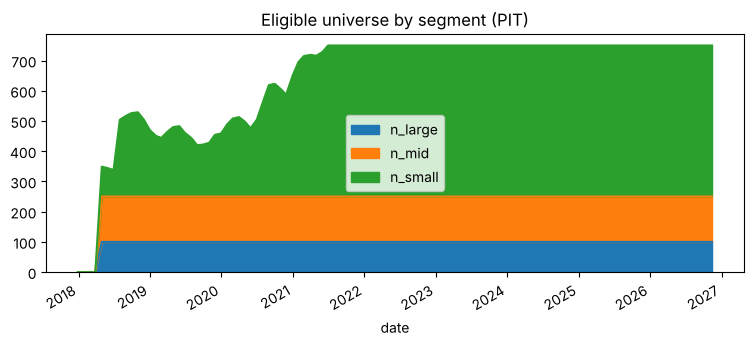

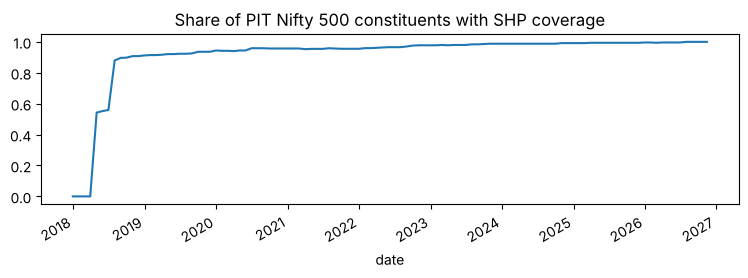

In [4]:
cov = pd.read_csv(T/'universe_coverage.csv', parse_dates=['date'])
ax = cov.set_index('date')[['n_large','n_mid','n_small']].plot.area(figsize=(9,3.5), title='Eligible universe by segment (PIT)'); plt.show()
cov.set_index('date')['nifty500_coverage'].plot(figsize=(9,2.5), title='Share of PIT Nifty 500 constituents with SHP coverage'); plt.show()

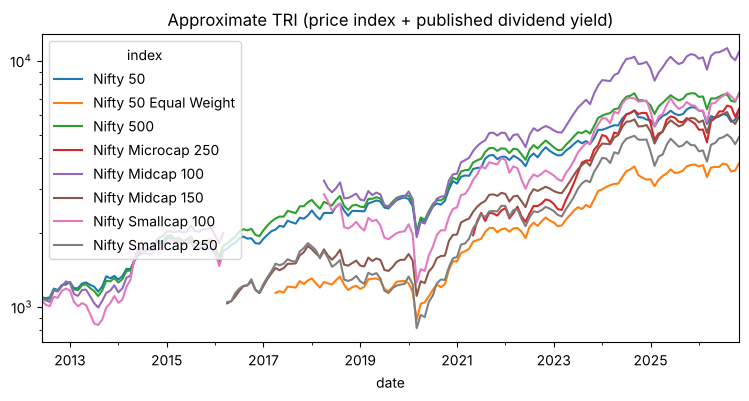

In [5]:
idx = pd.read_parquet(P/'index_levels.parquet')
idx.pivot(index='date', columns='index', values='tri').resample('ME').last().plot(logy=True, figsize=(9,4), title='Approximate TRI (price index + published dividend yield)'); plt.show()